In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

df = pd.read_csv("cleaned_players_data.csv")

# Model 1: Базалық бақылау айнымалылары
f1 = "log_market_value ~ age_centered + age_centered_sq + minutes_played + contract_years + C(club_tier) + C(league)"
# Model 2: + Позиция (Defender салыстырмалы топ)
f2 = f1 + ' + C(position, Treatment(reference="Defender"))'
# Model 3: + Позициялық өнімділік метрикалары (xg, prog_passes, tackles)
f3 = f2 + " + xg_filled + prog_passes_filled + tackles_filled"

m1 = smf.ols(f1, data=df).fit(cov_type="HC1")
m2 = smf.ols(f2, data=df).fit(cov_type="HC1")
m3 = smf.ols(f3, data=df).fit(cov_type="HC1")

print("=== MODEL 3 SUMMARY (RQ1: HC1 ROBUST SE) ===")
print(m3.summary())

comp = pd.DataFrame({
    "Model": ["Model 1: Controls Only", "Model 2: + Position", "Model 3: Full Specification"],
    "N": [int(m1.nobs), int(m2.nobs), int(m3.nobs)],
    "Adj_R2": [round(m1.rsquared_adj, 4), round(m2.rsquared_adj, 4), round(m3.rsquared_adj, 4)],
    "AIC": [round(m1.aic, 1), round(m2.aic, 1), round(m3.aic, 1)],
    "BIC": [round(m1.bic, 1), round(m2.bic, 1), round(m3.bic, 1)],
})
display(comp)

=== MODEL 3 SUMMARY (RQ1: HC1 ROBUST SE) ===
                            OLS Regression Results                            
Dep. Variable:       log_market_value   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                     399.0
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:33:43   Log-Likelihood:                -543.85
No. Observations:                1200   AIC:                             1120.
Df Residuals:                    1184   BIC:                             1201.
Df Model:                          15                                         
Covariance Type:                  HC1                                         
                                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

,Model,N,Adj_R2,AIC,BIC
0,Model 1: Controls Only,1200,0.8007,1400.4,1456.4
1,Model 2: + Position,1200,0.8432,1114.9,1181.1
2,Model 3: Full Specification,1200,0.8429,1119.7,1201.1


=== RQ2: PEAK VALUATION AGE BY POSITION ===


,Position,N,beta_age,beta_age_sq,p_value_age_sq,Peak_Age_Years
0,Forward,362,0.4497,-0.00576,0.0,39.03
1,Midfielder,407,0.4863,-0.00641,0.0,37.94
2,Defender,431,0.4846,-0.00628,0.0,38.58


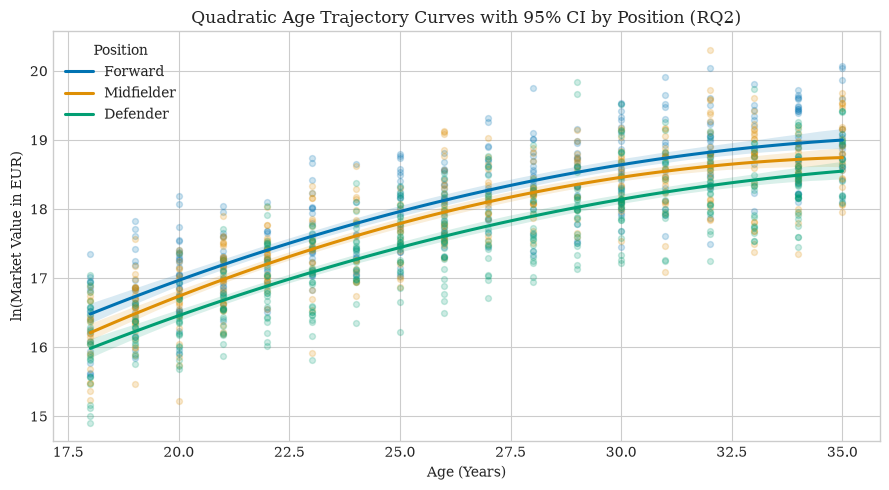

In [2]:
print("=== RQ2: PEAK VALUATION AGE BY POSITION ===")
peak_rows = []
for pos in ["Forward", "Midfielder", "Defender"]:
    sub = df[df["position"] == pos]
    m_age = smf.ols("log_market_value ~ age + age_sq + minutes_played + contract_years + C(club_tier) + C(league)", data=sub).fit(cov_type="HC1")
    b1, b2 = m_age.params["age"], m_age.params["age_sq"]
    peak = -b1 / (2 * b2) if b2 < 0 else np.nan
    peak_rows.append({
        "Position": pos,
        "N": int(m_age.nobs),
        "beta_age": round(b1, 4),
        "beta_age_sq": round(b2, 5),
        "p_value_age_sq": round(m_age.pvalues["age_sq"], 5),
        "Peak_Age_Years": round(peak, 2)
    })
display(pd.DataFrame(peak_rows))

# Figure 3: Позициялар бойынша параболалық жас қисығы
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
plt.rcParams.update({"font.family": "serif", "font.size": 10})

fig, ax = plt.subplots(figsize=(9, 5))
for pos in ["Forward", "Midfielder", "Defender"]:
    sub = df[df["position"] == pos]
    sns.regplot(
        data=sub, x="age", y="log_market_value", order=2,
        scatter_kws={"alpha": 0.2, "s": 18}, line_kws={"linewidth": 2.2, "label": pos}, ax=ax
    )
ax.set_title("Quadratic Age Trajectory Curves with 95% CI by Position (RQ2)")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("ln(Market Value in EUR)")
ax.legend(title="Position")
fig.tight_layout()
fig.savefig("fig3_age_valuation_curves.png", dpi=300, bbox_inches="tight")
fig.savefig("fig3_age_valuation_curves.pdf", bbox_inches="tight")
plt.show()

In [3]:
print("=== RQ3: POSITION-SPECIFIC PERFORMANCE METRICS IMPACT ===")
rq3_rows = []
pos_configs = [
    ("Forward", "xg_per90"),
    ("Midfielder", "prog_passes_per90"),
    ("Defender", "tackles_per90"),
]

for pos, metric in pos_configs:
    sub = df[df["position"] == pos].dropna(subset=[metric])
    m_base = smf.ols("log_market_value ~ age_centered + age_centered_sq + minutes_played + contract_years + C(club_tier) + C(league)", data=sub).fit(cov_type="HC1")
    m_ext = smf.ols(f"log_market_value ~ age_centered + age_centered_sq + minutes_played + contract_years + C(club_tier) + C(league) + {metric}", data=sub).fit(cov_type="HC1")
    rq3_rows.append({
        "Position": pos,
        "Specific_Metric": metric,
        "N": int(m_ext.nobs),
        "Metric_Coef": round(m_ext.params[metric], 4),
        "p_value": round(m_ext.pvalues[metric], 5),
        "Base_Adj_R2": round(m_base.rsquared_adj, 4),
        "With_Metric_Adj_R2": round(m_ext.rsquared_adj, 4),
    })

display(pd.DataFrame(rq3_rows))

=== RQ3: POSITION-SPECIFIC PERFORMANCE METRICS IMPACT ===


,Position,Specific_Metric,N,Metric_Coef,p_value,Base_Adj_R2,With_Metric_Adj_R2
0,Forward,xg_per90,362,-0.0910,0.38961,0.8311,0.8309
1,Midfielder,prog_passes_per90,407,-0.0060,0.61388,0.8503,0.8500
2,Defender,tackles_per90,431,0.0129,0.67504,0.8285,0.8282
